# Model performance and sensitivity analyses

This notebook evaluates how input selection and baseline specification affect reconstruction of observed all-cause mortality. Its model-input comparison supplies the performance values summarized in **Manuscript Figure 5**, while the period-specific and sensitivity heatmaps support **Supplementary Figures 3-5**.

Daily RMSE and R² are calculated for the full study period and for influenza-season, summer, pre-pandemic, pandemic, validation, and 2025 test windows. Sensitivity panels compare exposure inputs, adaptive-baseline methods, humidity indicators, and mean-alignment settings. Lower RMSE indicates better reconstruction.

## Execution mode

Set `EXECUTION_DEVICE` in the first code cell to `"auto"`, `"cpu"`, or `"cuda"`. Auto mode uses CUDA when available and CPU otherwise. CPU mode evaluates only the `v0` checkpoint and therefore does not reproduce ensemble-median manuscript values; CUDA mode evaluates the complete 10-checkpoint ensemble.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the repository root')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from notebooks import load_checkpoint, load_experiment, resolve_device

EXECUTION_DEVICE = "auto"
DEVICE = resolve_device(EXECUTION_DEVICE)

In [2]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "lines.linewidth": 1.2,
    "grid.alpha": 0.4,
})

## Define model comparisons

The experiment registry groups configurations by input signals, baseline method, humidity representation, and mean-alignment setting. Each label below is used consistently in the metric tables and heatmaps.

In [3]:

set_up = {'sari_COVID' : 'HeatMortality_EXP_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1',
          't_only' : 'HeatMortality_EXP_t_6_median_ewma_corr_on_pop_average_tas_stage1',
          't_sari' : 'HeatMortality_EXP_t_6_sari_10_median_ewma_corr_on_pop_average_tas-tdew_stage1',
          'baseline_static' : 'HeatMortality_EXP_t_6_sari_10_covid_corr_on_pop_average_tas-tdew_stage1',
          'baseline_adaptive' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1',
          'tas_only' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas_stage1',
          'tas_wetbulb' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-twb_stage1',
          'baseline_trimmed_mean' : 'HeatMortality_EXP_t_6_sari_10_covid_trimmed_avg_corr_on_pop_average_tas-tdew_stage1',
          'baseline_ewma_double_side' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_d_corr_on_pop_average_tas-tdew_stage1',
          'corr_off' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_off_pop_average_tas-tdew_stage1',
            'corr_on' : 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1'}


## Reconstruct daily national mortality

For each configuration, checkpoint predictions are aggregated across district, age, and sex and then averaged across the selected ensemble members. The observed series is constructed from the same daily national mortality labels.

In [4]:
def load_model_and_predictions(experiment_name: str):
    m, checkpoint_paths = load_experiment(experiment_name, DEVICE)

    preds = []

    with torch.no_grad():
        for checkpoint_path in checkpoint_paths:
            load_checkpoint(m, checkpoint_path, DEVICE)
            m.evaluate_baseline()
            m._compute_predictions(random_t_sigma=0)
            if m.config.correct_training_mean:
                mort = m.daily_predictions_corrected.cpu().detach()
            else:
                mort = m.daily_predictions.cpu().detach()
            preds.append(mort.sum((1, 2, 3)))
    return m, preds

model = {}
res = {}
for key, run_dir in set_up.items():
    model[key], res[key] = load_model_and_predictions(run_dir)
    print(key)

sari_COVID
t_only
t_sari
baseline_static
baseline_adaptive
tas_only
tas_wetbulb
baseline_trimmed_mean
baseline_ewma_double_side
corr_off
corr_on


In [5]:
k = list(set_up.keys())[0]
val = torch.cat([model[k].train_labels.daily_land, model[k].val_labels.daily_land]).sum([1]).cpu()
tr = {k: torch.stack(res[k]).mean(0) for k in set_up.keys()}

In [6]:
df = pd.DataFrame({'date': pd.date_range(start='2014-10-13', end='2025-12-28', freq='D')})
df['year'] = df['date'].dt.year
df['week'] = df['date'].dt.isocalendar().week

## Period-specific reconstruction metrics

RMSE and R² are evaluated for epidemiologically and chronologically defined windows. The influenza season spans ISO weeks 40-20, while the summer period spans weeks 15-38. Validation covers 2023-2024 and the held-out test period is 2025.

In [7]:
import warnings
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore', category=DeprecationWarning)

mask_by_period = {
    'Overall': np.ones(len(df), dtype=bool),
    'Influenza Season': ((df['week'] >= 40) | (df['week'] <= 20)).to_numpy(),
    'Summer Period': ((df['week'] >= 15) & (df['week'] <= 38)).to_numpy(),
    'Pre-pandemic': (df['year'] <= 2019).to_numpy(),
    'Pandemic': ((df['year'] >= 2020) & (df['year'] <= 2022)).to_numpy(),
    'Validation': ((df['year'] >= 2023) & (df['year'] <= 2024)).to_numpy(),
    'Test': ((df['year'] >= 2025)).to_numpy(),
}

def rmse(x):
    return (x.pow(2).mean().sqrt()).item()

rmse_dict = {}
r2_dict = {}
time_period = list(mask_by_period.keys())

for k, pred in tr.items():
    print(f'{k:25s}', end=' ')
    diff = pred - val
    rmse_vals = [rmse(diff[m.copy()]) for m in mask_by_period.values()]
    print(''.join(f'{v:10.2f}' for v in rmse_vals))

    r2_vals = [r2_score(pred[m], val[m]) for m in mask_by_period.values()]
    print(f'{" ":26s}' + ''.join(f'{v:10.4f}' for v in r2_vals))

    rmse_dict[k] = rmse_vals
    r2_dict[k] = r2_vals

sari_COVID                    117.13    103.45    131.05    118.86    122.02    109.01    108.37
                              0.8465    0.8812    0.2076    0.7839    0.8479    0.8067    0.8549
t_only                        170.18    201.17    108.47    156.18    188.42    192.09    131.11
                              0.6836    0.5290    0.6223    0.5527    0.6714    0.6207    0.7595
t_sari                         82.84     87.23     74.99     71.99     94.21     87.73     89.05
                              0.9305    0.9204    0.8280    0.9320    0.9150    0.8896    0.9190
baseline_static               128.90    133.56    119.52     81.24    113.16    193.77    196.49
                              0.8634    0.8547    0.7085    0.9052    0.9043    0.4959    0.6798
baseline_adaptive              80.17     83.21     74.41     72.47     89.40     82.34     84.59
                              0.9343    0.9271    0.8260    0.9273    0.9280    0.9004    0.9201
tas_only                      

/local/job_25157817/ipykernel_411120/1383241772.py:29: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  r2_vals = [r2_score(pred[m], val[m]) for m in mask_by_period.values()]


In [8]:
tr_keys = list(tr.keys())
rmse_tensor = torch.tensor([rmse_dict[k] for k in tr_keys])
r2_tensor = torch.tensor([r2_dict[k] for k in tr_keys])

## Input-component sensitivity

This panel compares respiratory-infection-only, weather-only, weather plus non-COVID SARI, and the full hybrid configuration. These results provide the model-input comparison summarized compactly in Manuscript Figure 5 and the detailed period comparison in the supplement.

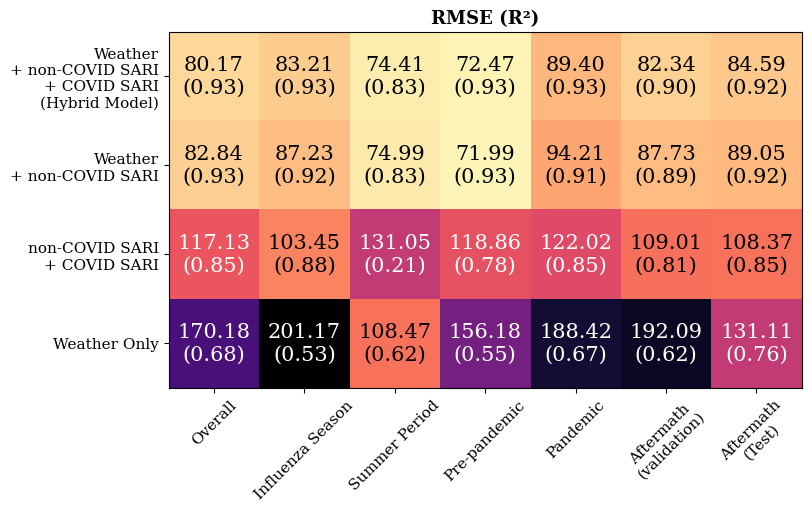

In [9]:
from matplotlib.colors import Normalize

norm = Normalize(vmin=rmse_tensor.min(), vmax=rmse_tensor.max())
windows = ['Overall', 'Influenza Season', 'Summer Period', 'Pre-pandemic', 'Pandemic', 'Aftermath\n(validation)', 'Aftermath\n(Test)']

def heat(ax, data, data_aux, row_labels, col_labels, title, cmap='magma', reverse=False, norm=None):
    cmap_obj = plt.get_cmap(cmap).reversed() if reverse else plt.get_cmap(cmap)
    im = ax.imshow(data, aspect='auto', cmap=cmap_obj, norm=norm)
    ax.set_xticks(np.arange(len(col_labels)))
    ax.set_xticklabels(col_labels, rotation=45)
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels)
    ax.set_title(title)

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            v_aux = data_aux[i, j]
            r, g, b, _ = cmap_obj(norm(v)) if norm is not None else cmap_obj(v)
            luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
            color = 'black' if luminance > 0.5 else 'white'
            ax.text(j, i, f'{v:.2f}\n({v_aux:.2f})', ha='center', va='center', color=color, fontsize=15)
    return im

def plot_model_heatmap(model_labels, idx, title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True):
    rmse_arr = rmse_tensor[idx].numpy()
    r2_arr = r2_tensor[idx].numpy()
    order = np.argsort(rmse_arr.mean(axis=1))
    rmse_arr, r2_arr = rmse_arr[order], r2_arr[order]
    labels = [model_labels[i] for i in order]

    fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=True)
    heat(ax, rmse_arr, r2_arr, labels, windows, title, cmap=cmap, reverse=reverse, norm=norm)
    return fig, ax

models_input = [
    'non-COVID SARI\n+ COVID SARI',
    'Weather Only',
    'Weather\n+ non-COVID SARI',
    'Weather\n+ non-COVID SARI\n+ COVID SARI\n(Hybrid Model)',
]

plot_model_heatmap(models_input, [0, 1, 2, 4], title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True)
# plt.savefig('model_comparison_input.png', dpi=300, bbox_inches='tight')
plt.show()

## Baseline-method sensitivity

Static, median-EWMA, trimmed-mean, and double-sided median-EWMA baselines are compared using the same reconstruction metrics. This analysis tests whether the hybrid model's performance depends on one particular background-mortality definition.

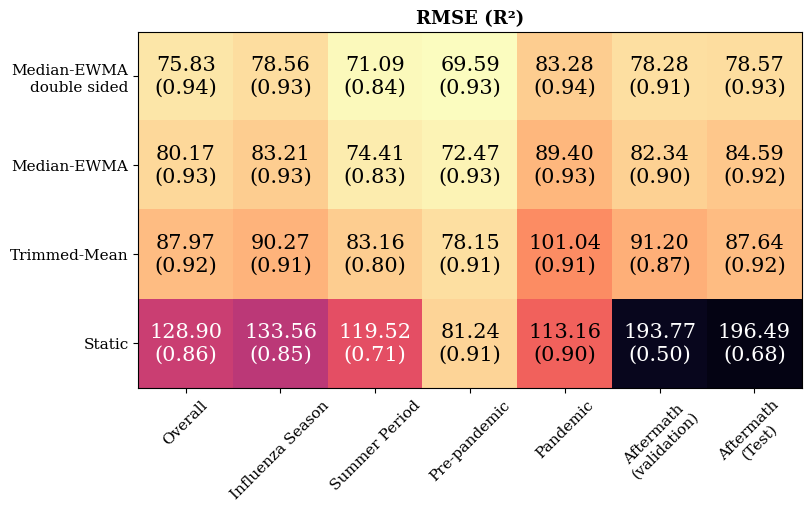

In [10]:
models_baseline = ['Static', 'Median-EWMA', 'Trimmed-Mean', 'Median-EWMA\ndouble sided']
plot_model_heatmap(models_baseline, [3, 4, 7, 8], title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True)
# plt.savefig('model_comparison_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

## Humidity-indicator sensitivity

The final comparison evaluates air temperature plus dew point, air temperature alone, and air temperature plus wet-bulb temperature. It complements the fitted response curves in Manuscript Figure 2 with reconstruction-based evidence.

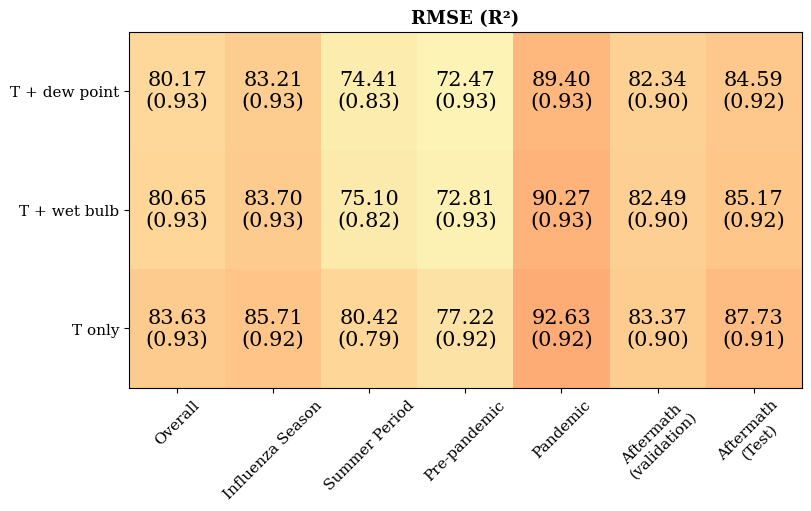

In [11]:
models_weather = ['T + dew point', 'T only', 'T + wet bulb']
plot_model_heatmap(models_weather, [4, 5, 6], title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True)
# plt.savefig('model_comparison_humidity.png', dpi=300, bbox_inches='tight')
plt.show()